In [1]:
import os
print(os.getcwd())
print(os.listdir())                          # should show 'face-mask-dataset'
print(os.listdir("face-mask-dataset"))        # should show ['with_mask', 'without_mask']
print(len(os.listdir("face-mask-dataset/with_mask")))     # image count
print(len(os.listdir("face-mask-dataset/without_mask")))  # image count

C:\Users\hp\OneDrive\Desktop\face mask deteection project
['.ipynb_checkpoints', 'face-mask-dataset', 'mask_detection.ipynb']
['without_mask', 'with_mask']
3725
3828


In [2]:
DATA_DIR = "face-mask-dataset"

In [3]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

In [4]:
IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 30

# Point this to the folder that directly CONTAINS with_mask/ and without_mask/
DATA_DIR = "face-mask-dataset"

In [6]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.15,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.15,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode="nearest",
    validation_split=0.2          # 80% train / 20% val
)

train_gen = train_datagen.flow_from_directory(
    DATA_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="training",            # <- picks the 80% split
    shuffle=True,
    seed=42
)


Found 6043 images belonging to 2 classes.


In [8]:
val_gen = train_datagen.flow_from_directory(
    DATA_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation",          # <- picks the 20% split
    shuffle=False,
    seed=42 )

Found 1510 images belonging to 2 classes.


In [9]:
print("Class indices:", train_gen.class_indices)

Class indices: {'with_mask': 0, 'without_mask': 1}


In [10]:
model = Sequential([
    Conv2D(32, (3, 3), activation="relu", padding="same",
           input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    BatchNormalization(),
    MaxPooling2D(2, 2),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D(2, 2),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D(2, 2),

    Conv2D(256, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D(2, 2),

    Flatten(),
    Dense(256, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])


C:\Users\hp\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [11]:
model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Precision(name="precision"),
             tf.keras.metrics.Recall(name="recall")]
)

In [12]:
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,585,153 (17.49 MB)

 Trainable params: 4,584,193 (17.49 MB)

 Non-trainable params: 960 (3.75 KB)

In [13]:
callbacks = [
    EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
    ModelCheckpoint("best_simple_cnn_mask.h5", monitor="val_accuracy",
                     save_best_only=True, verbose=1)
]

In [14]:
history = model.fit(
    train_gen,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks
)

Epoch 1/30
 81/189 ━━━━━━━━━━━━━━━━━━━━ 3:32 2s/step - accuracy: 0.7407 - loss: 1.3269 - precision: 0.7467 - recall: 0.7399

C:\Users\hp\anaconda3\Lib\site-packages\PIL\Image.py:1039: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7892 - loss: 0.8217 - precision: 0.8054 - recall: 0.7702
Epoch 1: val_accuracy improved from None to 0.52053, saving model to best_simple_cnn_mask.h5



Epoch 1: finished saving model to best_simple_cnn_mask.h5
189/189 ━━━━━━━━━━━━━━━━━━━━ 430s 2s/step - accuracy: 0.7892 - loss: 0.8217 - precision: 0.8054 - recall: 0.7702 - val_accuracy: 0.5205 - val_loss: 3.0510 - val_precision: 0.5138 - val_recall: 0.9961 - learning_rate: 0.0010
Epoch 2/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8719 - loss: 0.3251 - precision: 0.8907 - recall: 0.8518
Epoch 2: val_accuracy improved from 0.52053 to 0.79536, saving model to best_simple_cnn_mask.h5



Epoch 2: finished saving model to best_simple_cnn_mask.h5
189/189 ━━━━━━━━━━━━━━━━━━━━ 322s 2s/step - accuracy: 0.8719 - loss: 0.3251 - precision: 0.8907 - recall: 0.8518 - val_accuracy: 0.7954 - val_loss: 0.6033 - val_precision: 0.7303 - val_recall: 0.9451 - learning_rate: 0.0010
Epoch 3/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8895 - loss: 0.2792 - precision: 0.9028 - recall: 0.8763
Epoch 3: val_accuracy did not improve from 0.79536
189/189 ━━━━━━━━━━━━━━━━━━━━ 322s 2s/step - accuracy: 0.8895 - loss: 0.2792 - precision: 0.9028 - recall: 0.8763 - val_accuracy: 0.6940 - val_loss: 0.7509 - val_precision: 0.9840 - val_recall: 0.4026 - learning_rate: 0.0010
Epoch 4/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9184 - loss: 0.2232 - precision: 0.9272 - recall: 0.9105
Epoch 4: val_accuracy improved from 0.79536 to 0.89272, saving model to best_simple_cnn_mask.h5



Epoch 4: finished saving model to best_simple_cnn_mask.h5
189/189 ━━━━━━━━━━━━━━━━━━━━ 307s 2s/step - accuracy: 0.9184 - loss: 0.2232 - precision: 0.9272 - recall: 0.9105 - val_accuracy: 0.8927 - val_loss: 0.3118 - val_precision: 0.8331 - val_recall: 0.9856 - learning_rate: 0.0010
Epoch 5/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9330 - loss: 0.1925 - precision: 0.9357 - recall: 0.9318
Epoch 5: val_accuracy did not improve from 0.89272
189/189 ━━━━━━━━━━━━━━━━━━━━ 309s 2s/step - accuracy: 0.9330 - loss: 0.1925 - precision: 0.9357 - recall: 0.9318 - val_accuracy: 0.7093 - val_loss: 0.5955 - val_precision: 0.9738 - val_recall: 0.4379 - learning_rate: 0.0010
Epoch 6/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9414 - loss: 0.1606 - precision: 0.9419 - recall: 0.9425
Epoch 6: val_accuracy improved from 0.89272 to 0.93377, saving model to best_simple_cnn_mask.h5


... (4 outputs left out)


Epoch 15: finished saving model to best_simple_cnn_mask.h5
189/189 ━━━━━━━━━━━━━━━━━━━━ 394s 2s/step - accuracy: 0.9765 - loss: 0.0715 - precision: 0.9790 - recall: 0.9745 - val_accuracy: 0.9695 - val_loss: 0.0737 - val_precision: 0.9813 - val_recall: 0.9582 - learning_rate: 5.0000e-04
Epoch 16/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9775 - loss: 0.0640 - precision: 0.9791 - recall: 0.9765
Epoch 16: val_accuracy improved from 0.96954 to 0.97483, saving model to best_simple_cnn_mask.h5



Epoch 16: finished saving model to best_simple_cnn_mask.h5
189/189 ━━━━━━━━━━━━━━━━━━━━ 560s 3s/step - accuracy: 0.9775 - loss: 0.0640 - precision: 0.9791 - recall: 0.9765 - val_accuracy: 0.9748 - val_loss: 0.0719 - val_precision: 0.9789 - val_recall: 0.9712 - learning_rate: 5.0000e-04
Epoch 17/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9778 - loss: 0.0643 - precision: 0.9791 - recall: 0.9771
Epoch 17: val_accuracy did not improve from 0.97483
189/189 ━━━━━━━━━━━━━━━━━━━━ 274s 1s/step - accuracy: 0.9778 - loss: 0.0643 - precision: 0.9791 - recall: 0.9771 - val_accuracy: 0.9550 - val_loss: 0.1211 - val_precision: 0.9580 - val_recall: 0.9529 - learning_rate: 5.0000e-04
Epoch 18/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9831 - loss: 0.0536 - precision: 0.9840 - recall: 0.9827
Epoch 18: val_accuracy did not improve from 0.97483
189/189 ━━━━━━━━━━━━━━━━━━━━ 320s 2s/step - accuracy: 0.9831 - loss: 0.0536 - precision: 0.9840 - recall: 0.9827 - val_accuracy: 0.968


Epoch 22: finished saving model to best_simple_cnn_mask.h5
189/189 ━━━━━━━━━━━━━━━━━━━━ 266s 1s/step - accuracy: 0.9871 - loss: 0.0385 - precision: 0.9882 - recall: 0.9863 - val_accuracy: 0.9801 - val_loss: 0.0473 - val_precision: 0.9779 - val_recall: 0.9830 - learning_rate: 2.5000e-04
Epoch 23/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9863 - loss: 0.0378 - precision: 0.9872 - recall: 0.9856
Epoch 23: val_accuracy improved from 0.98013 to 0.98278, saving model to best_simple_cnn_mask.h5



Epoch 23: finished saving model to best_simple_cnn_mask.h5
189/189 ━━━━━━━━━━━━━━━━━━━━ 281s 1s/step - accuracy: 0.9863 - loss: 0.0378 - precision: 0.9872 - recall: 0.9856 - val_accuracy: 0.9828 - val_loss: 0.0486 - val_precision: 0.9868 - val_recall: 0.9791 - learning_rate: 2.5000e-04
Epoch 24/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9901 - loss: 0.0277 - precision: 0.9899 - recall: 0.9905
Epoch 24: val_accuracy did not improve from 0.98278
189/189 ━━━━━━━━━━━━━━━━━━━━ 358s 2s/step - accuracy: 0.9901 - loss: 0.0277 - precision: 0.9899 - recall: 0.9905 - val_accuracy: 0.9748 - val_loss: 0.0613 - val_precision: 0.9642 - val_recall: 0.9869 - learning_rate: 2.5000e-04
Epoch 25/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9904 - loss: 0.0311 - precision: 0.9909 - recall: 0.9902
Epoch 25: val_accuracy did not improve from 0.98278
189/189 ━━━━━━━━━━━━━━━━━━━━ 310s 2s/step - accuracy: 0.9904 - loss: 0.0311 - precision: 0.9909 - recall: 0.9902 - val_accuracy: 0.978

In [15]:
val_loss, val_acc, val_prec, val_rec = model.evaluate(val_gen)
print(f"\nValidation Accuracy : {val_acc*100:.2f}%")
print(f"Validation Precision: {val_prec*100:.2f}%")
print(f"Validation Recall   : {val_rec*100:.2f}%")

preds = (model.predict(val_gen) > 0.5).astype(int).flatten() 
true_labels = val_gen.classes

print("\nClassification Report:")
print(classification_report(true_labels, preds,
      target_names=list(val_gen.class_indices.keys())))

print("Confusion Matrix:")
print(confusion_matrix(true_labels, preds))


48/48 ━━━━━━━━━━━━━━━━━━━━ 28s 569ms/step - accuracy: 0.9801 - loss: 0.0572 - precision: 0.9893 - recall: 0.9712

Validation Accuracy : 98.01%
Validation Precision: 98.93%
Validation Recall   : 97.12%
48/48 ━━━━━━━━━━━━━━━━━━━━ 29s 588ms/step

Classification Report:
              precision    recall  f1-score   support

   with_mask       0.97      0.99      0.98       745
without_mask       0.99      0.97      0.98       765

    accuracy                           0.98      1510
   macro avg       0.98      0.98      0.98      1510
weighted avg       0.98      0.98      0.98      1510

Confusion Matrix:
[[736   9]
 [ 20 745]]


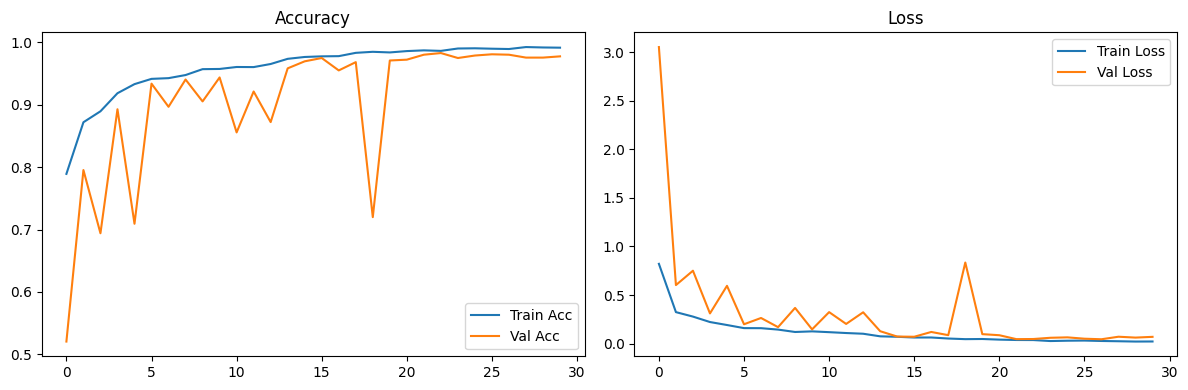

In [17]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Acc")
plt.plot(history.history["val_accuracy"], label="Val Acc")
plt.legend(); plt.title("Accuracy")

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.legend(); plt.title("Loss")
plt.tight_layout()
plt.savefig("training_curves.png")
plt.show()